In [ ]:
import numpy as np
import re
import random
import matplotlib.pyplot as plt
import math
from collections import Counter, defaultdict
from datasets import load_dataset

In [ ]:
dataset = load_dataset(
    "parquet",
    data_files={
        "train": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/train-00000-of-00001.parquet",
        "test": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/test-00000-of-00001.parquet"
    }
)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 8937
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 2013
    })
})


In [ ]:
all_train_data = dataset["train"]

np.random.seed(42)

indices = np.random.permutation(len(all_train_data))

split_point = int(0.8 * len(indices))

train_indices = indices[:split_point]
validation_indices = indices[split_point:]

train_data = all_train_data.select(train_indices)
validation_data = all_train_data.select(validation_indices)

test_data = dataset["test"]

print("Training sentences:", len(train_data))
print("Validation sentences:", len(validation_data))
print("Testing sentences:", len(test_data))

Training sentences: 7149
Validation sentences: 1788
Testing sentences: 2013


In [ ]:
def preprocess_sentence(sentence):
    return [
        token.strip()
        for token in sentence
        if token.strip()
    ]
train_sentences = [
    preprocess_sentence(s)
    for s in train_data["tokens"]
]

validation_sentences = [
    preprocess_sentence(s)
    for s in validation_data["tokens"]
]

test_sentences = [
    preprocess_sentence(s)
    for s in test_data["tokens"]
]

print("Original sentence:", train_data["tokens"][0])
print("Processed sentence:", train_sentences[0])

Original sentence: ['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']
Processed sentence: ['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']


In [ ]:
word_counts = Counter()

for sentence in train_sentences:

    for word in sentence:

        word_counts[word] += 1

print("Total unique words:", len(word_counts))
print(word_counts.most_common(10))

Total unique words: 17178
[(',', 8573), ('the', 7439), ('.', 6976), ('of', 4162), ('to', 4065), ('a', 3454), ('and', 2877), ('in', 2681), ("'s", 1562), ('for', 1521)]


In [ ]:
for min_count in [1, 2, 4, 10, 20]:
    vocabulary = []

    for word in word_counts:
        if word_counts[word] >= min_count:
            vocabulary.append(word)

    print("Minimum count:", min_count)
    print("Vocabulary size:", len(vocabulary))
    print("----------------------")

Minimum count: 1
Vocabulary size: 17178
----------------------
Minimum count: 2
Vocabulary size: 8493
----------------------
Minimum count: 4
Vocabulary size: 4551
----------------------
Minimum count: 10
Vocabulary size: 2045
----------------------
Minimum count: 20
Vocabulary size: 1035
----------------------


In [ ]:
min_count = 2

vocabulary = []

for word in word_counts:
    if word_counts[word] >= min_count:
        vocabulary.append(word)

word_to_id = {}

for i in range(len(vocabulary)):
    word_to_id[vocabulary[i]] = i

id_to_word = {}

for word in word_to_id:
    id_to_word[word_to_id[word]] = word

print("Final vocabulary size:", len(vocabulary))

Final vocabulary size: 8493


In [ ]:
unknown_validation = 0
total_validation = 0

for sentence in validation_sentences:
    for word in sentence:
        total_validation += 1

        if word not in word_to_id:
            unknown_validation += 1

unknown_test = 0
total_test = 0

for sentence in test_sentences:
    for word in sentence:
        total_test += 1

        if word not in word_to_id:
            unknown_test += 1

print("Unknown validation words:", unknown_validation)
print("Validation unknown percentage:", 100 * unknown_validation / total_validation)

print("Unknown test words:", unknown_test)
print("Test unknown percentage:", 100 * unknown_test / total_test)

Unknown validation words: 3352
Validation unknown percentage: 7.966726084373144
Unknown test words: 5063
Test unknown percentage: 10.686620089917048


In [ ]:
def build_cooccurrence(sentences, window_size):

    cooccurrence = {}

    for sentence in sentences:

        for i in range(len(sentence)):

            center_word = sentence[i]

            if center_word not in word_to_id:
                continue

            if center_word not in cooccurrence:
                cooccurrence[center_word] = {}

            start = max(0, i - window_size)
            end = min(len(sentence), i + window_size + 1)

            for j in range(start, end):

                if i == j:
                    continue

                context_word = sentence[j]

                if context_word not in word_to_id:
                    continue

                if context_word not in cooccurrence[center_word]:
                    cooccurrence[center_word][context_word] = 0

                cooccurrence[center_word][context_word] += 1

    return cooccurrence

In [ ]:
for window in [1, 2, 3, 4]:

    cooccurrence = build_cooccurrence(train_sentences, window)

    number_of_pairs = 0

    for word in cooccurrence:
        number_of_pairs += len(cooccurrence[word])

    print("Window size:", window)
    print("Different word pairs:", number_of_pairs)
    print("----------------------")

Window size: 1
Different word pairs: 138901
----------------------
Window size: 2
Different word pairs: 266556
----------------------
Window size: 3
Different word pairs: 378696
----------------------
Window size: 4
Different word pairs: 477701
----------------------


In [ ]:
def calculate_ppmi(cooccurrence):

    total = 0
    word_counts_pmi = {}
    context_counts = {}

    for word in cooccurrence:

        word_counts_pmi[word] = 0

        for context in cooccurrence[word]:

            count = cooccurrence[word][context]

            total += count
            word_counts_pmi[word] += count

            if context not in context_counts:
                context_counts[context] = 0

            context_counts[context] += count

    ppmi = {}

    for word in cooccurrence:

        ppmi[word] = {}

        for context in cooccurrence[word]:

            count = cooccurrence[word][context]

            pmi = math.log(
                (count * total) /
                (word_counts_pmi[word] * context_counts[context])
            )

            if pmi > 0:
                ppmi[word][context] = pmi

    return ppmi

In [ ]:
ppmi_results = {}

for window in [1, 2, 3,5]:

    cooccurrence = build_cooccurrence(train_sentences, window)

    ppmi_results[window] = calculate_ppmi(cooccurrence)

    print("Window:", window)
    print("Number of PPMI words:", len(ppmi_results[window]))
    print("----------------------")

Window: 1
Number of PPMI words: 8493
----------------------
Window: 2
Number of PPMI words: 8493
----------------------
Window: 3
Number of PPMI words: 8493
----------------------
Window: 5
Number of PPMI words: 8493
----------------------


In [ ]:
def sparse_cosine(vector1, vector2):

    dot = 0

    for word in vector1:

        if word in vector2:
            dot += vector1[word] * vector2[word]

    norm1 = 0
    norm2 = 0

    for value in vector1.values():
        norm1 += value ** 2

    for value in vector2.values():
        norm2 += value ** 2

    norm1 = math.sqrt(norm1)
    norm2 = math.sqrt(norm2)

    if norm1 == 0 or norm2 == 0:
        return 0

    return dot / (norm1 * norm2)

In [ ]:
def find_sparse_neighbors(query_word, vectors, number=5):

    if query_word not in vectors:
        return []

    similarities = []

    for word in vectors:

        if word == query_word:
            continue

        similarity = sparse_cosine(
            vectors[query_word],
            vectors[word]
        )

        similarities.append((word, similarity))

    similarities.sort(key=lambda x: x[1], reverse=True)

    return similarities[:number]

In [ ]:
query_word = "market"

for window in [1, 2, 3]:

    print("Window size:", window)

    neighbors = find_sparse_neighbors(
        query_word,
        ppmi_results[window]
    )

    print(neighbors)
    print("----------------------")

Window size: 1
[('stock-market', 0.17445095853876724), ('arena', 0.14621094825362946), ('cost-cutting', 0.11569393317202872), ('sector', 0.109116114595603), ('stabilize', 0.1029649544501835)]
----------------------
Window size: 2
[('stock', 0.15169601041198053), ('plunge', 0.13799469393587116), ('stock-market', 0.12236156889533133), ('arena', 0.11749128729524012), ('Friday', 0.1082931755554003)]
----------------------
Window size: 3
[('stock', 0.18123949662794786), ('Friday', 0.1298590173011267), ('the', 0.12256711865331883), ('a', 0.11040303270737385), ('participants', 0.11013781228167885)]
----------------------


In [ ]:
term_frequency = {}
document_frequency = {}

number_of_documents = len(train_sentences)

for i in range(number_of_documents):

    sentence = train_sentences[i]

    word_counts_in_document = Counter(sentence)

    for word in word_counts_in_document:

        if word not in word_to_id:
            continue

        if word not in term_frequency:
            term_frequency[word] = {}

        term_frequency[word][i] = word_counts_in_document[word]

        if word not in document_frequency:
            document_frequency[word] = 0

        document_frequency[word] += 1

print("Words with TF:", len(term_frequency))

Words with TF: 8493


In [ ]:
idf_results = {}

for formula in [1, 2, 3]:

    idf_results[formula] = {}

    for word in document_frequency:

        df = document_frequency[word]

        if formula == 1:
            idf = math.log((number_of_documents + 1) / (df + 1)) + 1

        elif formula == 2:
            idf = math.log((number_of_documents + 1) / (df + 1))

        else:
            idf = math.log(number_of_documents / df)

        idf_results[formula][word] = idf

    print("IDF formula:", formula)
    print("Example IDF:", list(idf_results[formula].items())[:5])
    print("----------------------")

IDF formula: 1
Example IDF: [('One', 5.849515944952904), ('of', 1.8635125265267676), ('the', 1.507567533846433), ('advantages', 8.265429723253952), ('hot-dipped', 7.795426094008217)]
----------------------
IDF formula: 2
Example IDF: [('One', 4.849515944952904), ('of', 0.8635125265267676), ('the', 0.5075675338464329), ('advantages', 7.265429723253953), ('hot-dipped', 6.795426094008217)]
----------------------
IDF formula: 3
Example IDF: [('One', 4.867394580534381), ('of', 0.863704386580411), ('the', 0.5076600329282521), ('advantages', 7.488433404646961), ('hot-dipped', 6.928817616711538)]
----------------------


In [ ]:
idf = idf_results[1]

tfidf_vectors = {}

for word in term_frequency:

    tfidf_vectors[word] = {}

    for document in term_frequency[word]:

        tf = term_frequency[word][document]

        tfidf = tf * idf[word]

        tfidf_vectors[word][document] = tfidf

print("Number of TF-IDF word vectors:", len(tfidf_vectors))

Number of TF-IDF word vectors: 8493


In [ ]:
for formula in [1, 2, 3]:

    current_vectors = {}

    for word in term_frequency:

        current_vectors[word] = {}

        for document in term_frequency[word]:

            tf = term_frequency[word][document]

            current_vectors[word][document] = tf * idf_results[formula][word]

    print("IDF formula:", formula)

    print(
        find_sparse_neighbors(
            "market",
            current_vectors
        )
    )

    print("----------------------")

IDF formula: 1
[('the', 0.2151747209704054), ('stock', 0.20168305912502513), ('.', 0.1900144783569308), ('makers', 0.18955164088291002), ('plunge', 0.1501110699893031)]
----------------------
IDF formula: 2
[('the', 0.21517472097040763), ('stock', 0.20168305912502474), ('.', 0.1900144783569313), ('makers', 0.1895516408829097), ('plunge', 0.15011106998930288)]
----------------------
IDF formula: 3
[('the', 0.21517472097040158), ('stock', 0.20168305912502368), ('.', 0.19001447835691415), ('makers', 0.18955164088290924), ('plunge', 0.1501110699893025)]
----------------------


In [ ]:
# Convert training sentences into IDs
train_ids = [
    [word_to_id.get(word, None) for word in sentence]
    for sentence in train_sentences
]

# Convert validation sentences into IDs
validation_ids = [
    [word_to_id.get(word, None) for word in sentence]
    for sentence in validation_sentences
]

print("Training sentences:", len(train_ids))
print("Validation sentences:", len(validation_ids))

# Check an example
print("Original sentence:", train_sentences[0])
print("ID sentence:", train_ids[0])

Training sentences: 7149
Validation sentences: 1788
Original sentence: ['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']
ID sentence: [0, 1, 2, 3, 1, 2, 4, 5, 6, 7, 8, 9, 2, 10, 11, 12, 13, 14, 15, None, None, 1, None, 16, 17, 18]


In [ ]:
def generate_pairs(sentences, window_size):

    pairs = []

    for sentence in sentences:

        for i, center_word in enumerate(sentence):

            if center_word is None:
                continue

            start = max(0, i - window_size)
            end = min(len(sentence), i + window_size + 1)

            for j in range(start, end):

                if i == j:
                    continue

                context_word = sentence[j]

                # Skip unknown context words
                if context_word is None:
                    continue

                pairs.append((center_word, context_word))

    return pairs

In [ ]:
for window in [1, 2, 3]:

    pairs = generate_pairs(train_ids, window)

    print("Window size:", window)
    print("Number of training pairs:", len(pairs))
    print("----------------------")

Window size: 1
Number of training pairs: 292796
----------------------
Window size: 2
Number of training pairs: 573166
----------------------
Window size: 3
Number of training pairs: 841020
----------------------


In [ ]:
vocab_size = len(vocabulary)

embedding_dim = 50
negative_samples = 5
learning_rate = 0.025
epochs = 10
window_size = 2

print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Negative samples:", negative_samples)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)

Vocabulary size: 8493
Embedding dimension: 50
Negative samples: 5
Learning rate: 0.025
Epochs: 10


In [ ]:
np.random.seed(42)
random.seed(42)

input_embeddings = np.random.uniform(
    -0.5 / embedding_dim,
    0.5 / embedding_dim,
    (vocab_size, embedding_dim)
)

output_embeddings = np.zeros(
    (vocab_size, embedding_dim)
)

print("Input embeddings:", input_embeddings.shape)
print("Output embeddings:", output_embeddings.shape)

Input embeddings: (8493, 50)
Output embeddings: (8493, 50)


In [ ]:
word_frequencies = np.zeros(vocab_size)

for word, word_id in word_to_id.items():

    word_frequencies[word_id] = word_counts[word]

negative_distribution = word_frequencies ** 0.75

negative_distribution /= negative_distribution.sum()

print("Negative distribution sum:", negative_distribution.sum())

Negative distribution sum: 1.0


In [ ]:
def sigmoid(x):

    x = np.clip(x, -15, 15)

    return 1 / (1 + np.exp(-x))

In [ ]:
def train_pair(
    center_id,
    context_id,
    input_embeddings,
    output_embeddings,
    negative_distribution,
    negative_samples,
    learning_rate,
    rng
):

    # Get center embedding
    center_vector = input_embeddings[center_id].copy()

    # Get positive context embedding
    positive_vector = output_embeddings[context_id].copy()

    # --------------------------------
    # 1. Positive forward computation
    # --------------------------------

    positive_score = np.dot(center_vector, positive_vector)

    positive_probability = sigmoid(positive_score)

    positive_loss = np.logaddexp(0, -positive_score)

    # --------------------------------
    # 2. Positive gradients
    # --------------------------------
    positive_gradient = positive_probability - 1

    center_gradient = positive_gradient * positive_vector

    positive_output_gradient = positive_gradient * center_vector

    # --------------------------------
    # 3. Negative sampling
    # --------------------------------

    negative_ids = []

    while len(negative_ids) < negative_samples:

        negative_id = rng.choice(
            len(negative_distribution),
            p=negative_distribution
        )

        # Exclude the actual positive context
        if negative_id != context_id:
            negative_ids.append(negative_id)

    negative_loss = 0

    negative_output_gradients = {}

    # --------------------------------
    # 4. Negative forward computation
    # --------------------------------

    for negative_id in negative_ids:

        negative_vector = output_embeddings[negative_id].copy()

        negative_score = np.dot(center_vector, negative_vector)

        negative_probability = sigmoid(negative_score)

        negative_loss += np.logaddexp(0, negative_score)

        # --------------------------------
        # 5. Negative gradients
        # --------------------------------

        negative_gradient = negative_probability

        center_gradient += negative_gradient * negative_vector

        if negative_id not in negative_output_gradients:
            negative_output_gradients[negative_id] = np.zeros_like(center_vector)

        negative_output_gradients[negative_id] += (
            negative_gradient * center_vector
        )

    # --------------------------------
    # 6. Update input embedding
    # --------------------------------

    input_embeddings[center_id] -= (
        learning_rate * center_gradient
    )
    # --------------------------------
    # 7. Update positive output embedding
    # --------------------------------

    output_embeddings[context_id] -= (
        learning_rate * positive_output_gradient
    )

    # --------------------------------
    # 8. Update negative output embeddings
    # --------------------------------

    for negative_id, gradient in negative_output_gradients.items():

        output_embeddings[negative_id] -= (
            learning_rate * gradient
        )

    return positive_loss + negative_loss
training_pairs = generate_pairs(train_ids, window_size)

validation_pairs = generate_pairs(validation_ids, window_size)

print("Training pairs:", len(training_pairs))
print("Validation pairs:", len(validation_pairs))

Training pairs: 573166
Validation pairs: 133748


generate the negative samples once and reuse them for every epoch and experiment.

In [ ]:
def generate_validation_negatives(
    pairs,
    negative_distribution,
    negative_samples,
    seed=42
):

    rng = np.random.default_rng(seed)

    validation_negatives = np.zeros(
        (len(pairs), negative_samples),
        dtype=int
    )

    for i, (center_id, context_id) in enumerate(pairs):

        negatives = []

        while len(negatives) < negative_samples:

            negative_id = rng.choice(
                len(negative_distribution),
                p=negative_distribution
            )

            if negative_id != context_id:
                negatives.append(negative_id)

        validation_negatives[i] = negatives

    return validation_negatives

In [ ]:
def calculate_validation_loss(
    pairs,
    validation_negatives,
    input_embeddings,
    output_embeddings
):

    total_loss = 0

    for i, (center_id, context_id) in enumerate(pairs):

        center_vector = input_embeddings[center_id]

        # Positive score
        positive_vector = output_embeddings[context_id]

        positive_score = np.dot(
            center_vector,
            positive_vector
        )

        loss = np.logaddexp(0, -positive_score)

        # Negative scores
        for negative_id in validation_negatives[i]:

            negative_vector = output_embeddings[negative_id]

            negative_score = np.dot(
                center_vector,
                negative_vector
            )

            loss += np.logaddexp(0, negative_score)

        total_loss += loss

    if len(pairs) == 0:
        return 0

    return total_loss / len(pairs)

In [ ]:
def train_epoch(
    training_pairs,
    input_embeddings,
    output_embeddings,
    negative_distribution,
    negative_samples,
    learning_rate,
    rng
):

    shuffled_indices = rng.permutation(len(training_pairs))

    total_loss = 0

    for index in shuffled_indices:

        center_id, context_id = training_pairs[index]

        loss = train_pair(
            center_id,
            context_id,
            input_embeddings,
            output_embeddings,
            negative_distribution,
            negative_samples,
            learning_rate,
            rng
        )

        total_loss += loss

    return total_loss / len(training_pairs)

In [ ]:
experiments = [
    [1, 50, 0.025],
    [2, 50, 0.025],
    [3, 50, 0.025],
    [2, 100, 0.025],
    [2, 100, 0.01],
    [3, 100, 0.025]
]

results = []

tuning_negative_samples = 5
tuning_epochs = 3

max_training_pairs = 20000
max_validation_pairs = 5000

for experiment_number, experiment in enumerate(experiments):

    window, dimension, rate = experiment

    print("Testing:", experiment)

    # Generate pairs for this window size
    current_training_pairs = generate_pairs(
        train_ids,
        window
    )

    current_validation_pairs = generate_pairs(
        validation_ids,
        window
    )

    # Use reproducible subsets for tuning
    tuning_rng = np.random.default_rng(100 + experiment_number)

    if len(current_training_pairs) > max_training_pairs:

        indices = tuning_rng.choice(
            len(current_training_pairs),
            max_training_pairs,
            replace=False
        )

        current_training_pairs = [
            current_training_pairs[i] for i in indices
        ]

    if len(current_validation_pairs) > max_validation_pairs:

        indices = tuning_rng.choice(
            len(current_validation_pairs),
            max_validation_pairs,
            replace=False
        )

        current_validation_pairs = [
            current_validation_pairs[i] for i in indices
        ]

    # Fixed validation negatives
    current_validation_negatives = generate_validation_negatives(
        current_validation_pairs,
        negative_distribution,
        tuning_negative_samples,
        seed=42
    )

    # Initialize fresh embeddings for every experiment
    current_input = np.random.default_rng(42).uniform(
        -0.5 / dimension,
        0.5 / dimension,
        (vocab_size, dimension)
    )

    current_output = np.zeros(
        (vocab_size, dimension)
    )

    rng = np.random.default_rng(1000 + experiment_number)

    # Train
    for epoch in range(tuning_epochs):

        train_loss = train_epoch(
            current_training_pairs,
            current_input,
            current_output,
            negative_distribution,
            tuning_negative_samples,
            rate,
            rng
        )

    # Evaluate
    validation_loss = calculate_validation_loss(
        current_validation_pairs,
        current_validation_negatives,
        current_input,
        current_output
    )

    results.append({
        "window": window,
        "dimension": dimension,
        "negative_samples": tuning_negative_samples,
        "learning_rate": rate,
        "validation_loss": validation_loss
    })

    print("Validation loss:", validation_loss)
    print("----------------------")

Testing: [1, 50, 0.025]
Validation loss: 3.8261906840445854
----------------------
Testing: [2, 50, 0.025]
Validation loss: 3.8988223510696662
----------------------
Testing: [3, 50, 0.025]
Validation loss: 3.9072382372049788
----------------------
Testing: [2, 100, 0.025]
Validation loss: 3.9264778041002
----------------------
Testing: [2, 100, 0.01]
Validation loss: 4.1557269157139896
----------------------
Testing: [3, 100, 0.025]
Validation loss: 3.9382451136679117
----------------------


In [ ]:
results.sort(key=lambda x: x["validation_loss"])

print("Hyperparameter results:\n")

for result in results:

    print(
        "Window:", result["window"],
        "| Dimension:", result["dimension"],
        "| Negative samples:", result["negative_samples"],
        "| Learning rate:", result["learning_rate"],
        "| Validation loss:", round(result["validation_loss"], 4)
    )

best_result = results[0]

print("\nBest configuration:")
print(best_result)

Hyperparameter results:

Window: 1 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.8262
Window: 2 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.8988
Window: 3 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9072
Window: 2 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9265
Window: 3 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9382
Window: 2 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.01 | Validation loss: 4.1557

Best configuration:
{'window': 1, 'dimension': 50, 'negative_samples': 5, 'learning_rate': 0.025, 'validation_loss': np.float64(3.8261906840445854)}


In [ ]:
window_size = best_result["window"]
embedding_dim = best_result["dimension"]
negative_samples = best_result["negative_samples"]
learning_rate = best_result["learning_rate"]

print("Selected window:", window_size)
print("Selected dimension:", embedding_dim)
print("Selected negative samples:", negative_samples)
print("Selected learning rate:", learning_rate)

Selected window: 1
Selected dimension: 50
Selected negative samples: 5
Selected learning rate: 0.025


In [ ]:
training_pairs = generate_pairs(
    train_ids,
    window_size
)

validation_pairs = generate_pairs(
    validation_ids,
    window_size
)

# Fixed validation negatives
validation_negatives = generate_validation_negatives(
    validation_pairs,
    negative_distribution,
    negative_samples,
    seed=42
)

print("Final training pairs:", len(training_pairs))
print("Final validation pairs:", len(validation_pairs))
rng = np.random.default_rng(42)

input_embeddings = rng.uniform(
    -0.5 / embedding_dim,
    0.5 / embedding_dim,
    (vocab_size, embedding_dim)
)

output_embeddings = np.zeros(
    (vocab_size, embedding_dim)
)

print("Input embedding shape:", input_embeddings.shape)
print("Output embedding shape:", output_embeddings.shape)

Final training pairs: 292796
Final validation pairs: 68296
Input embedding shape: (8493, 50)
Output embedding shape: (8493, 50)


In [ ]:
training_losses = []
validation_losses = []

best_validation_loss = float("inf")
best_embeddings = None

patience = 2
epochs_without_improvement = 0
max_epochs = 10

for epoch in range(max_epochs):

    # Train on all training pairs
    training_loss = train_epoch(
        training_pairs,
        input_embeddings,
        output_embeddings,
        negative_distribution,
        negative_samples,
        learning_rate,
        rng
    )

    # Evaluate on fixed validation pairs and negatives
    validation_loss = calculate_validation_loss(
        validation_pairs,
        validation_negatives,
        input_embeddings,
        output_embeddings
    )

    training_losses.append(training_loss)
    validation_losses.append(validation_loss)

    print("Epoch:", epoch + 1)
    print("Training loss:", round(training_loss, 4))
    print("Validation loss:", round(validation_loss, 4))
    print("----------------------")

    # Save the best model
    if validation_loss < best_validation_loss:

        best_validation_loss = validation_loss

        best_embeddings = input_embeddings.copy()

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:

        print("Early stopping.")
        break

# Keep the best learned input embeddings
word2vec_embeddings = best_embeddings.copy()

print("Best validation loss:", best_validation_loss)
print("Epochs completed:", len(training_losses))
print("Final embedding shape:", word2vec_embeddings.shape)

Epoch: 1
Training loss: 3.4394
Validation loss: 2.8763
----------------------
Epoch: 2
Training loss: 2.6783
Validation loss: 2.4635
----------------------
Epoch: 3
Training loss: 2.3822
Validation loss: 2.293
----------------------
Epoch: 4
Training loss: 2.2164
Validation loss: 2.1973
----------------------
Epoch: 5
Training loss: 2.1054
Validation loss: 2.1477
----------------------
Epoch: 6
Training loss: 2.0176
Validation loss: 2.1053
----------------------
Epoch: 7
Training loss: 1.9454
Validation loss: 2.0873
----------------------
Epoch: 8
Training loss: 1.8856
Validation loss: 2.0735
----------------------
Epoch: 9
Training loss: 1.8326
Validation loss: 2.064
----------------------
Epoch: 10
Training loss: 1.7861
Validation loss: 2.0582
----------------------
Best validation loss: 2.0581535136967073
Epochs completed: 10
Final embedding shape: (8493, 50)


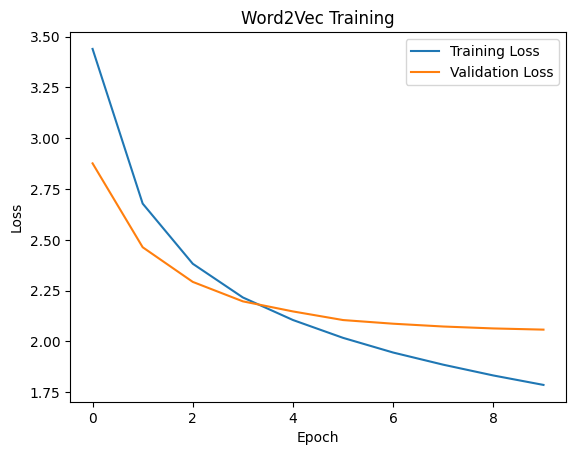

In [ ]:
plt.plot(training_losses, label="Training Loss")
plt.plot(validation_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Word2Vec Training")

plt.legend()
plt.show()

In [ ]:
def dense_cosine(vector1, vector2):

    norm1 = np.linalg.norm(vector1)
    norm2 = np.linalg.norm(vector2)

    if norm1 == 0 or norm2 == 0:
        return 0

    return np.dot(vector1, vector2) / (norm1 * norm2)

In [ ]:
def find_word2vec_neighbors(query_word, embeddings, number=5):

    if query_word not in word_to_id:
        return []

    query_id = word_to_id[query_word]

    similarities = []

    for word in word_to_id:

        word_id = word_to_id[word]

        if word == query_word:
            continue

        similarity = dense_cosine(
            embeddings[query_id],
            embeddings[word_id]
        )

        similarities.append((word, similarity))

    similarities.sort(key=lambda x: x[1], reverse=True)

    return similarities[:number]

In [ ]:
query_words = ["market", "government", "company", "people"]

for word in query_words:

    print("\nWORD:", word)

    print("PPMI:")
    print(find_sparse_neighbors(word, ppmi_results[window_size]))

    print("TF-IDF:")
    print(find_sparse_neighbors(word, tfidf_vectors))

    print("Word2Vec:")
    print(find_word2vec_neighbors(word, word2vec_embeddings))


WORD: market
PPMI:
[('stock-market', 0.17445095853876724), ('arena', 0.14621094825362946), ('cost-cutting', 0.11569393317202872), ('sector', 0.109116114595603), ('stabilize', 0.1029649544501835)]
TF-IDF:
[('the', 0.2151747209704054), ('stock', 0.20168305912502513), ('.', 0.1900144783569308), ('makers', 0.18955164088291002), ('plunge', 0.1501110699893031)]
Word2Vec:
[('markets', np.float64(0.6969667103958739)), ('world', np.float64(0.6387522656233341)), ('repurchases', np.float64(0.616101005436936)), ('split', np.float64(0.5937126401216885)), ('bank', np.float64(0.5847561562696588))]

WORD: government
PPMI:
[('bureaucracy', 0.13842807114342712), ('census', 0.115637707790366), ('enact', 0.11509946823286406), ('Constitution', 0.11313110882541798), ('300-day', 0.10738925588693382)]
TF-IDF:
[('the', 0.16188338013673048), ('Picop', 0.15271180544538157), ('.', 0.1327031278118717), ('of', 0.12811681615916645), ('federal', 0.12244184033406358)]
Word2Vec:
[('court', np.float64(0.752593502295211

In [ ]:
print("PPMI dimensions:", len(vocabulary), "x", len(vocabulary))

print("TF-IDF dimensions:", len(vocabulary), "x", number_of_documents)

print("Word2Vec dimensions:", word2vec_embeddings.shape)

PPMI dimensions: 8493 x 8493
TF-IDF dimensions: 8493 x 7149
Word2Vec dimensions: (8493, 50)


In [ ]:
ppmi_nonzero = 0

for word in ppmi_results[window_size]:

    ppmi_nonzero += len(ppmi_results[window_size][word])

tfidf_nonzero = 0

for word in tfidf_vectors:

    tfidf_nonzero += len(tfidf_vectors[word])

word2vec_nonzero = np.count_nonzero(word2vec_embeddings)

print("PPMI non-zero values:", ppmi_nonzero)
print("TF-IDF non-zero values:", tfidf_nonzero)
print("Word2Vec non-zero values:", word2vec_nonzero)

PPMI non-zero values: 131513
TF-IDF non-zero values: 143915
Word2Vec non-zero values: 424650


In [ ]:
vocab_size = len(vocabulary)

ppmi_density = ppmi_nonzero / (vocab_size * vocab_size)

tfidf_density = tfidf_nonzero / (vocab_size * number_of_documents)

word2vec_density = word2vec_nonzero / word2vec_embeddings.size

print("PPMI density:", ppmi_density)
print("TF-IDF density:", tfidf_density)
print("Word2Vec density:", word2vec_density)

PPMI density: 0.0018232508999002635
TF-IDF density: 0.0023702799390946014
Word2Vec density: 1.0


In [ ]:
ppmi_size = vocab_size * vocab_size * 8 / (1024 ** 2)

tfidf_size = vocab_size * number_of_documents * 8 / (1024 ** 2)

word2vec_size = word2vec_embeddings.size * 8 / (1024 ** 2)

print("PPMI dense storage (MB):", ppmi_size)
print("TF-IDF dense storage (MB):", tfidf_size)
print("Word2Vec storage (MB):", word2vec_size)

PPMI dense storage (MB): 550.3162307739258
TF-IDF dense storage (MB): 463.2298049926758
Word2Vec storage (MB): 3.2398223876953125


In [ ]:
import numpy as np
from collections import Counter
from datasets import load_dataset
import matplotlib.pyplot as plt

### 2. Load CoNLL-2000

The original training partition is used for training and validation; the original test partition is reserved for final evaluation.

In [ ]:
raw_dataset = load_dataset("eriktks/conll2000")

original_train_data = raw_dataset["train"]
original_test_data = raw_dataset["test"]

print("Original training sentences:", len(original_train_data))
print("Original test sentences:", len(original_test_data))
print("Available columns:", original_train_data.column_names)

RuntimeError: Dataset scripts are no longer supported, but found conll2000.py

### 3. Define the reproducible split

A fixed seed creates the same 90/10 sentence split each time. The returned indices let Part 1 reuse the exact split.

In [ ]:
def create_train_validation_split(training_data, validation_ratio=0.1, seed=42):
    indices = np.arange(len(training_data))

    rng = np.random.default_rng(seed)
    rng.shuffle(indices)

    validation_size = int(len(indices) * validation_ratio)
    validation_indices = indices[:validation_size].tolist()
    train_indices = indices[validation_size:].tolist()

    train_split = training_data.select(train_indices)
    validation_split = training_data.select(validation_indices)

    return train_split, validation_split, train_indices, validation_indices

### 4. Create the training and validation partitions

Use the same ratio, seed, and indices in Part 1. The test partition is not included.

In [ ]:
SEED = 42
VALIDATION_RATIO = 0.1

train_data, validation_data, train_indices, validation_indices = create_train_validation_split(
    original_train_data,
    validation_ratio=VALIDATION_RATIO,
    seed=SEED
)

test_data = original_test_data

print("Training sentences:", len(train_data))
print("Validation sentences:", len(validation_data))
print("Test sentences:", len(test_data))

# Part 2 — Hidden Markov Model and Viterbi

Implement a POS tagger using initial, transition, and emission probabilities, smoothing, an `UNK` strategy, and Viterbi decoding.

### 5. Extract tokens and POS tags

Convert POS IDs to readable tag names and prepare the original training data for final retraining. Chunk labels are not used.

In [ ]:
# Find the ClassLabel feature that contains the POS tag names.
pos_tag_feature = original_train_data.features["pos_tags"]
if hasattr(pos_tag_feature, "feature"):
    pos_tag_feature = pos_tag_feature.feature

pos_tag_names = getattr(pos_tag_feature, "names", None)


def convert_pos_tags(tag_sequence):
    if pos_tag_names is None:
        return [str(tag) for tag in tag_sequence]

    return [
        pos_tag_names[int(tag)] if isinstance(tag, (int, np.integer)) else str(tag)
        for tag in tag_sequence
    ]


def extract_sentences_and_tags(dataset_split):
    sentences = [list(tokens) for tokens in dataset_split["tokens"]]
    tag_sequences = [convert_pos_tags(tags) for tags in dataset_split["pos_tags"]]
    return sentences, tag_sequences


train_sentences, train_tags = extract_sentences_and_tags(train_data)
validation_sentences, validation_tags = extract_sentences_and_tags(validation_data)
test_sentences, test_tags = extract_sentences_and_tags(test_data)
full_train_sentences, full_train_tags = extract_sentences_and_tags(original_train_data)

### 6. Check the prepared data

Check the split sizes and inspect the extracted tokens and POS tags.

In [ ]:
print("Training sentences:", len(train_sentences))
print("Validation sentences:", len(validation_sentences))
print("Test sentences:", len(test_sentences))
print("Unique POS tags:", len({tag for sequence in train_tags for tag in sequence}))

print("\nExample sentence:", train_sentences[0])
print("Example POS tags:", train_tags[0])

assert len(train_sentences) == len(train_tags)
assert len(validation_sentences) == len(validation_tags)
assert len(test_sentences) == len(test_tags)
assert all(len(words) == len(tags) for words, tags in zip(train_sentences, train_tags))
assert all(len(words) == len(tags) for words, tags in zip(validation_sentences, validation_tags))
assert all(len(words) == len(tags) for words, tags in zip(test_sentences, test_tags))

: 

### 7. Handle unknown words

Keep capitalization and punctuation. Rare training words and unseen validation/test words are mapped to `UNK`.

In [ ]:
UNK_TOKEN = "<UNK>"

### 8. Train the HMM

Estimate initial, transition, and emission log probabilities from the training split using additive smoothing.

In [ ]:
def train_hmm(
    sentences,
    tag_sequences,
    min_word_frequency=2,
    alpha=0.1,
    beta=0.1,
    gamma=0.1
):
    # Count how often each word appears in the training sentences.
    word_frequencies = Counter(
        word for sentence in sentences for word in sentence
    )

    # Keep frequent words and reserve one vocabulary entry for unknown words.
    vocabulary = {
        word for word, count in word_frequencies.items()
        if count >= min_word_frequency
    }
    vocabulary.add(UNK_TOKEN)

    # Replace rare training words with UNK.
    processed_sentences = [
        [word if word in vocabulary else UNK_TOKEN for word in sentence]
        for sentence in sentences
    ]

    tags = sorted({tag for sequence in tag_sequences for tag in sequence})
    number_of_tags = len(tags)
    vocabulary_size = len(vocabulary)

    initial_counts = Counter()
    transition_counts = {tag: Counter() for tag in tags}
    emission_counts = {tag: Counter() for tag in tags}
    tag_counts = Counter()

    # Collect the HMM counts from the tagged training sentences.
    for words, sentence_tags in zip(processed_sentences, tag_sequences):
        if not words:
            continue

        initial_counts[sentence_tags[0]] += 1

        for word, tag in zip(words, sentence_tags):
            emission_counts[tag][word] += 1
            tag_counts[tag] += 1

        for previous_tag, current_tag in zip(sentence_tags[:-1], sentence_tags[1:]):
            transition_counts[previous_tag][current_tag] += 1

    # Initial log probabilities with additive smoothing.
    number_of_sentences = sum(initial_counts.values())
    log_initial = np.array([
        np.log(
            (initial_counts[tag] + gamma)
            / (number_of_sentences + gamma * number_of_tags)
        )
        for tag in tags
    ])

    # Transition log-probability matrix: rows = previous tags, columns = current tags.
    log_transition = np.zeros((number_of_tags, number_of_tags))

    for previous_index, previous_tag in enumerate(tags):
        outgoing_count = sum(transition_counts[previous_tag].values())
        denominator = outgoing_count + alpha * number_of_tags

        for current_index, current_tag in enumerate(tags):
            probability = (
                transition_counts[previous_tag][current_tag] + alpha
            ) / denominator
            log_transition[previous_index, current_index] = np.log(probability)

    # Store observed emission log probabilities and a fallback for zero-count words.
    log_emission = {}
    log_unk_emission = {}

    for tag in tags:
        denominator = tag_counts[tag] + beta * vocabulary_size

        log_unk_emission[tag] = np.log(beta / denominator)
        log_emission[tag] = {
            word: np.log((count + beta) / denominator)
            for word, count in emission_counts[tag].items()
        }

    return {
        "tags": tags,
        "vocabulary": vocabulary,
        "log_initial": log_initial,
        "log_transition": log_transition,
        "log_emission": log_emission,
        "log_unk_emission": log_unk_emission,
        "min_word_frequency": min_word_frequency,
        "alpha": alpha,
        "beta": beta,
        "gamma": gamma
    }

### 9. Viterbi decoding

Use dynamic programming and backpointers to find the most likely tag sequence. Log probabilities help avoid numerical underflow.

In [ ]:
def viterbi(sentence, hmm):
    if not sentence:
        return []

    tags = hmm["tags"]
    number_of_tags = len(tags)

    # Map words outside the HMM vocabulary to UNK.
    words = [
        word if word in hmm["vocabulary"] else UNK_TOKEN
        for word in sentence
    ]

    # Initialize scores for the first word.
    first_emission_scores = np.array([
        hmm["log_emission"][tag].get(
            words[0], hmm["log_unk_emission"][tag]
        )
        for tag in tags
    ])
    scores = hmm["log_initial"] + first_emission_scores

    # Store the best previous tag for each position and current tag.
    backpointers = np.zeros((len(words), number_of_tags), dtype=int)

    for position in range(1, len(words)):
        # Each row is a previous tag; each column is a current tag.
        candidate_scores = scores[:, np.newaxis] + hmm["log_transition"]
        best_previous_tags = np.argmax(candidate_scores, axis=0)

        best_previous_scores = candidate_scores[
            best_previous_tags, np.arange(number_of_tags)
        ]

        emission_scores = np.array([
            hmm["log_emission"][tag].get(
                words[position], hmm["log_unk_emission"][tag]
            )
            for tag in tags
        ])

        scores = best_previous_scores + emission_scores
        backpointers[position] = best_previous_tags

    # Choose the best tag for the final word and backtrack.
    best_last_tag = int(np.argmax(scores))
    best_path = [best_last_tag]

    for position in range(len(words) - 1, 0, -1):
        previous_tag = backpointers[position, best_path[-1]]
        best_path.append(int(previous_tag))

    best_path.reverse()
    return [tags[tag_index] for tag_index in best_path]


def predict_sentences(sentences, hmm):
    return [viterbi(sentence, hmm) for sentence in sentences]

### 10. Evaluation metrics

Report token accuracy and macro/micro precision, recall, and F1, including separate results for unknown words.

In [ ]:
def calculate_metrics(true_values, predicted_values, labels):
    if not true_values:
        return None

    correct = sum(
        true_tag == predicted_tag
        for true_tag, predicted_tag in zip(true_values, predicted_values)
    )
    accuracy = correct / len(true_values)

    per_tag = {}
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for tag in labels:
        true_positive = sum(
            true_tag == tag and predicted_tag == tag
            for true_tag, predicted_tag in zip(true_values, predicted_values)
        )
        false_positive = sum(
            true_tag != tag and predicted_tag == tag
            for true_tag, predicted_tag in zip(true_values, predicted_values)
        )
        false_negative = sum(
            true_tag == tag and predicted_tag != tag
            for true_tag, predicted_tag in zip(true_values, predicted_values)
        )

        precision = (
            true_positive / (true_positive + false_positive)
            if true_positive + false_positive > 0 else 0.0
        )
        recall = (
            true_positive / (true_positive + false_negative)
            if true_positive + false_negative > 0 else 0.0
        )
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0.0
        )

        per_tag[tag] = {
            "precision": precision,
            "recall": recall,
            "f1": f1
        }

        total_tp += true_positive
        total_fp += false_positive
        total_fn += false_negative

    macro_precision = np.mean([scores["precision"] for scores in per_tag.values()])
    macro_recall = np.mean([scores["recall"] for scores in per_tag.values()])
    macro_f1 = np.mean([scores["f1"] for scores in per_tag.values()])

    micro_precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0.0
    )
    micro_recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0.0
    )
    micro_f1 = (
        2 * micro_precision * micro_recall / (micro_precision + micro_recall)
        if micro_precision + micro_recall > 0 else 0.0
    )

    return {
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "micro_precision": micro_precision,
        "micro_recall": micro_recall,
        "micro_f1": micro_f1,
        "per_tag": per_tag
    }


def evaluate_hmm(sentences, true_tag_sequences, predicted_tag_sequences, vocabulary, tags):
    all_true = []
    all_predicted = []
    unknown_true = []
    unknown_predicted = []

    for words, true_tags, predicted_tags in zip(
        sentences, true_tag_sequences, predicted_tag_sequences
    ):
        for word, true_tag, predicted_tag in zip(words, true_tags, predicted_tags):
            all_true.append(true_tag)
            all_predicted.append(predicted_tag)

            if word not in vocabulary:
                unknown_true.append(true_tag)
                unknown_predicted.append(predicted_tag)

    overall_metrics = calculate_metrics(all_true, all_predicted, tags)

    if unknown_true:
        unknown_labels = sorted(set(unknown_true) | set(unknown_predicted))
        unknown_metrics = calculate_metrics(
            unknown_true, unknown_predicted, unknown_labels
        )
    else:
        unknown_metrics = None

    return {
        "overall": overall_metrics,
        "unknown": unknown_metrics,
        "unknown_token_count": len(unknown_true)
    }


def print_metrics(results, title):
    print(title)
    print(f"Token accuracy:  {results['accuracy']:.4f}")
    print(f"Macro precision: {results['macro_precision']:.4f}")
    print(f"Macro recall:    {results['macro_recall']:.4f}")
    print(f"Macro F1:        {results['macro_f1']:.4f}")
    print(f"Micro precision: {results['micro_precision']:.4f}")
    print(f"Micro recall:    {results['micro_recall']:.4f}")
    print(f"Micro F1:        {results['micro_f1']:.4f}")

### 11. Tune on validation data

Compare vocabulary and smoothing settings using validation macro F1. The test set is not used for tuning.

In [ ]:
minimum_frequency_values = [1, 2, 3]
alpha_values = [0.1, 1.0]
beta_values = [0.1, 1.0]
gamma_values = [0.1, 1.0]

best_config = None
best_validation_f1 = -1.0
validation_results = []

for min_frequency in minimum_frequency_values:
    for alpha in alpha_values:
        for beta in beta_values:
            for gamma in gamma_values:
                model = train_hmm(
                    train_sentences,
                    train_tags,
                    min_word_frequency=min_frequency,
                    alpha=alpha,
                    beta=beta,
                    gamma=gamma
                )

                validation_predictions = predict_sentences(validation_sentences, model)
                results = evaluate_hmm(
                    validation_sentences,
                    validation_tags,
                    validation_predictions,
                    model["vocabulary"],
                    model["tags"]
                )

                validation_f1 = results["overall"]["macro_f1"]
                validation_results.append({
                    "min_word_frequency": min_frequency,
                    "alpha": alpha,
                    "beta": beta,
                    "gamma": gamma,
                    "validation_macro_f1": validation_f1
                })

                print(
                    f"min_frequency={min_frequency}, alpha={alpha}, beta={beta}, gamma={gamma}, "
                    f"validation macro F1={validation_f1:.4f}"
                )

                if validation_f1 > best_validation_f1:
                    best_validation_f1 = validation_f1
                    best_config = {
                        "min_word_frequency": min_frequency,
                        "alpha": alpha,
                        "beta": beta,
                        "gamma": gamma
                    }

print("\nBest settings:", best_config)
print(f"Best validation macro F1: {best_validation_f1:.4f}")

### 12. Validation results

Evaluate the selected configuration on the validation split, including unknown-word performance.

In [ ]:
validation_model = train_hmm(
    train_sentences,
    train_tags,
    **best_config
)

validation_predictions = predict_sentences(validation_sentences, validation_model)
validation_metrics = evaluate_hmm(
    validation_sentences,
    validation_tags,
    validation_predictions,
    validation_model["vocabulary"],
    validation_model["tags"]
)

print_metrics(validation_metrics["overall"], "Validation results — all tokens")
print("\nUnknown validation tokens:", validation_metrics["unknown_token_count"])

if validation_metrics["unknown"] is not None:
    print_metrics(validation_metrics["unknown"], "Validation results — unknown tokens")
else:
    print("No unknown validation tokens were found.")

### 13. Train the final HMM

Retrain with the selected hyperparameters using the complete original training partition.

In [ ]:
final_hmm = train_hmm(
    full_train_sentences,
    full_train_tags,
    **best_config
)

print("Number of POS tags:", len(final_hmm["tags"]))
print("HMM vocabulary size, including UNK:", len(final_hmm["vocabulary"]))
print("Selected settings:", best_config)

### 14. Final test evaluation

Evaluate once on the original test partition and report results for all tokens and unknown tokens separately.

In [ ]:
test_predictions = predict_sentences(test_sentences, final_hmm)

test_metrics = evaluate_hmm(
    test_sentences,
    test_tags,
    test_predictions,
    final_hmm["vocabulary"],
    final_hmm["tags"]
)

print_metrics(test_metrics["overall"], "Test results — all tokens")
print("\nNumber of unknown test tokens:", test_metrics["unknown_token_count"])

if test_metrics["unknown"] is not None:
    print_metrics(test_metrics["unknown"], "Test results — unknown tokens")
else:
    print("No unknown test tokens were found.")

### 15. Per-tag test results

Review precision, recall, and F1 for each POS tag.

In [ ]:
print(f"{'Tag':<10}{'Precision':>12}{'Recall':>12}{'F1':>12}")

for tag, scores in sorted(test_metrics["overall"]["per_tag"].items()):
    print(
        f"{tag:<10}"
        f"{scores['precision']:>12.4f}"
        f"{scores['recall']:>12.4f}"
        f"{scores['f1']:>12.4f}"
    )

### 16. Visualize test results

These plots summarize final test performance and highlight common tagging errors.

Compare the main evaluation metrics on the original test set.

In [ ]:
metric_names = ["Accuracy", "Macro precision", "Macro recall", "Macro F1"]
metric_values = [
    test_metrics["overall"]["accuracy"],
    test_metrics["overall"]["macro_precision"],
    test_metrics["overall"]["macro_recall"],
    test_metrics["overall"]["macro_f1"]
]

plt.figure(figsize=(8, 4))
bars = plt.bar(metric_names, metric_values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("HMM performance on the test set")
plt.xticks(rotation=15)

for bar, value in zip(bars, metric_values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

Compare accuracy on words seen in training with accuracy on unknown test words.

In [ ]:
known_correct = 0
known_total = 0
unknown_correct = 0
unknown_total = 0

for sentence, true_sequence, predicted_sequence in zip(
    test_sentences, test_tags, test_predictions
):
    for word, true_tag, predicted_tag in zip(
        sentence, true_sequence, predicted_sequence
    ):
        if word in final_hmm["vocabulary"]:
            known_total += 1
            known_correct += (true_tag == predicted_tag)
        else:
            unknown_total += 1
            unknown_correct += (true_tag == predicted_tag)

category_labels = []
category_accuracies = []
category_counts = []

if known_total:
    category_labels.append("Known words")
    category_accuracies.append(known_correct / known_total)
    category_counts.append(known_total)

if unknown_total:
    category_labels.append("Unknown words")
    category_accuracies.append(unknown_correct / unknown_total)
    category_counts.append(unknown_total)

plt.figure(figsize=(7, 4))
bars = plt.bar(category_labels, category_accuracies)
plt.ylim(0, 1)
plt.ylabel("Token accuracy")
plt.title("Test accuracy: known vs. unknown words")

for bar, accuracy, count in zip(bars, category_accuracies, category_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.015,
        f"{accuracy:.3f} (n={count})",
        ha="center"
    )

plt.tight_layout()
plt.show()

Tags with lower F1 scores are harder for the HMM to predict.

In [ ]:
per_tag_scores = test_metrics["overall"]["per_tag"]
ordered_tags = sorted(
    per_tag_scores,
    key=lambda tag: per_tag_scores[tag]["f1"]
)
f1_values = [per_tag_scores[tag]["f1"] for tag in ordered_tags]

figure_height = max(6, len(ordered_tags) * 0.28)
plt.figure(figsize=(9, figure_height))
plt.barh(ordered_tags, f1_values)
plt.xlim(0, 1)
plt.xlabel("F1 score")
plt.ylabel("POS tag")
plt.title("Test F1 score by POS tag (lowest first)")
plt.tight_layout()
plt.show()

The confusion matrix shows which POS tags are mistaken for other tags. Rows are true tags and columns are predicted tags.

In [ ]:
all_true_tags = [tag for sequence in test_tags for tag in sequence]
all_predicted_tags = [tag for sequence in test_predictions for tag in sequence]
evaluation_tags = sorted(set(all_true_tags) | set(all_predicted_tags))
tag_to_index = {tag: index for index, tag in enumerate(evaluation_tags)}

confusion_matrix = np.zeros(
    (len(evaluation_tags), len(evaluation_tags)),
    dtype=int
)

for true_tag, predicted_tag in zip(all_true_tags, all_predicted_tags):
    confusion_matrix[tag_to_index[true_tag], tag_to_index[predicted_tag]] += 1

# Normalize each row so the chart shows proportions for each true POS tag.
row_totals = confusion_matrix.sum(axis=1, keepdims=True)
normalized_confusion_matrix = np.divide(
    confusion_matrix,
    row_totals,
    out=np.zeros_like(confusion_matrix, dtype=float),
    where=row_totals != 0
)

figure_size = max(9, len(evaluation_tags) * 0.25)
fig, ax = plt.subplots(figsize=(figure_size, figure_size * 0.85))
image = ax.imshow(normalized_confusion_matrix, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(len(evaluation_tags)))
ax.set_yticks(range(len(evaluation_tags)))
ax.set_xticklabels(evaluation_tags, rotation=90, fontsize=7)
ax.set_yticklabels(evaluation_tags, fontsize=7)
ax.set_xlabel("Predicted POS tag")
ax.set_ylabel("True POS tag")
ax.set_title("Normalized POS-tag confusion matrix")
fig.colorbar(image, ax=ax, label="Proportion")
fig.tight_layout()
plt.show()

This chart highlights the most frequent incorrect tag assignments.

In [ ]:
error_counts = Counter(
    (true_tag, predicted_tag)
    for true_tag, predicted_tag in zip(all_true_tags, all_predicted_tags)
    if true_tag != predicted_tag
)
most_common_errors = error_counts.most_common(10)

if most_common_errors:
    error_labels = [f"{true_tag} → {predicted_tag}" for (true_tag, predicted_tag), _ in most_common_errors]
    error_values = [count for _, count in most_common_errors]

    plt.figure(figsize=(8, 5))
    plt.barh(error_labels[::-1], error_values[::-1])
    plt.xlabel("Number of errors")
    plt.ylabel("True tag → predicted tag")
    plt.title("10 most common POS-tagging errors")
    plt.tight_layout()
    plt.show()
else:
    print("No tagging errors were found in the test set.")

### 17. Example tagging errors

Inspect a few incorrect predictions with their surrounding context.

In [ ]:
number_of_errors_to_show = 15
shown_errors = 0

for sentence, true_sequence, predicted_sequence in zip(
    test_sentences, test_tags, test_predictions
):
    for index, (word, true_tag, predicted_tag) in enumerate(
        zip(sentence, true_sequence, predicted_sequence)
    ):
        if true_tag != predicted_tag:
            start = max(0, index - 2)
            end = min(len(sentence), index + 3)
            context = " ".join(sentence[start:end])

            print(f"Word: {word}")
            print(f"True tag: {true_tag} | Predicted tag: {predicted_tag}")
            print(f"Context: {context}\n")

            shown_errors += 1
            if shown_errors >= number_of_errors_to_show:
                break

    if shown_errors >= number_of_errors_to_show:
        break

if shown_errors == 0:
    print("No tagging errors were found in the inspected sentences.")

## Part 2 — Summary

Record the selected hyperparameters, test metrics, unknown-word results, and notable tagging errors.

part3 

In [ ]:
# Select the Part 1 representations

part3_representations = {
    "PMI": ppmi_results[2],
    "TF-IDF": tfidf_vectors,
    "Word2Vec": word2vec_embeddings
}

print("PMI representation words:", len(part3_representations["PMI"]))
print("TF-IDF representation words:", len(part3_representations["TF-IDF"]))
print("Word2Vec representation shape:", part3_representations["Word2Vec"].shape)

In [ ]:
word_tag_counts = defaultdict(Counter)
tag_counts = Counter()
\
for sentence, tags in zip(train_sentences, train_tags):

    for word, tag in zip(sentence, tags):

        # Count every training tag, including rare words
        tag_counts[tag] += 1

        # Store word-specific tag counts only for HMM vocabulary words
        if word in final_hmm["vocabulary"]:

            word_tag_counts[word][tag] += 1


total_tag_count = sum(tag_counts.values())

tag_priors = {
    tag: count / total_tag_count
    for tag, count in tag_counts.items()
}

print("Words with POS distributions:", len(word_tag_counts))
print("Tag priors:", tag_priors)

In [ ]:
def get_word_vector(word, representation, representation_name):

    # PPMI and TF-IDF are dictionaries of sparse vectors
    if representation_name in ["PMI", "TF-IDF"]:

        return representation.get(word, None)

    # Word2Vec uses word IDs to access rows in the embedding matrix
    elif representation_name == "Word2Vec":

        if word not in word_to_id:
            return None

        return representation[word_to_id[word]]

    return None

In [ ]:
def calculate_similarity(vector1, vector2, representation_name):

    if vector1 is None or vector2 is None:
        return 0

    if representation_name in ["PMI", "TF-IDF"]:

        return sparse_cosine(vector1, vector2)

    return dense_cosine(vector1, vector2)

In [ ]:
def average_sparse_vectors(vectors):

    combined = defaultdict(float)

    if not vectors:
        return None

    for vector in vectors:

        for feature, value in vector.items():

            combined[feature] += value

    number_of_vectors = len(vectors)

    return {
        feature: value / number_of_vectors
        for feature, value in combined.items()
    }
def average_dense_vectors(vectors):

    if not vectors:
        return None

    return np.mean(vectors, axis=0)

In [ ]:
def build_unknown_representation(
    sentence,
    position,
    representation,
    representation_name,
    context_window=2
):

    # First, check whether the word itself has a representation
    target_word = sentence[position]

    target_vector = get_word_vector(
        target_word,
        representation,
        representation_name
    )

    if target_vector is not None and len(target_vector) > 0:
        return target_vector

    # Otherwise, use surrounding known words
    context_vectors = []

    start = max(0, position - context_window)
    end = min(len(sentence), position + context_window + 1)

    for j in range(start, end):

        if j == position:
            continue

        context_word = sentence[j]

        vector = get_word_vector(
            context_word,
            representation,
            representation_name
        )

        if vector is not None:
            context_vectors.append(vector)

    # No usable surrounding representations
    if not context_vectors:
        return None

    # Average sparse or dense vectors
    if representation_name in ["PMI", "TF-IDF"]:

        return average_sparse_vectors(context_vectors)

    return average_dense_vectors(context_vectors)

In [ ]:
def find_similar_words(
    query_vector,
    representation,
    representation_name,
    number=10
):

    if query_vector is None:
        return []

    similarities = []

    # Candidate words must have both a representation and POS-tag information
    if representation_name in ["PMI", "TF-IDF"]:

        candidate_words = representation.keys()

    else:

        candidate_words = word_to_id.keys()

    for word in candidate_words:

        if word not in final_hmm["vocabulary"]:
            continue

        if word not in word_tag_counts:
            continue

        candidate_vector = get_word_vector(
            word,
            representation,
            representation_name
        )

        if candidate_vector is None:
            continue

        similarity = calculate_similarity(
            query_vector,
            candidate_vector,
            representation_name
        )

        if similarity > 0:

            similarities.append((word, similarity))

    similarities.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return similarities[:number]

In [ ]:
query_word = "market"

query_vector = get_word_vector(
    query_word,
    part3_representations["PMI"],
    "PMI"
)

print(
    find_similar_words(
        query_vector,
        part3_representations["PMI"],
        "PMI"
    )
)

In [ ]:
def get_similarity_tag_distribution(
    sentence,
    position,
    representation,
    representation_name,
    context_window=2,
    top_k=10
):

    query_vector = build_unknown_representation(
        sentence,
        position,
        representation,
        representation_name,
        context_window
    )

    if query_vector is None:
        return None

    similar_words = find_similar_words(
        query_vector,
        representation,
        representation_name,
        number=top_k
    )

    if not similar_words:
        return None

    tag_distribution = Counter()

    total_similarity = sum(
        similarity
        for word, similarity in similar_words
    )

    if total_similarity == 0:
        return None

    # Weight each candidate's POS distribution by its similarity
    for word, similarity in similar_words:

        word_tag_total = sum(word_tag_counts[word].values())

        for tag, count in word_tag_counts[word].items():

            word_tag_probability = count / word_tag_total

            tag_distribution[tag] += (
                similarity / total_similarity
            ) * word_tag_probability

    # Normalize the final POS distribution
    total_probability = sum(tag_distribution.values())

    if total_probability == 0:
        return None

    return {
        tag: probability / total_probability
        for tag, probability in tag_distribution.items()
    }

In [ ]:
def get_emission_score(
    word,
    sentence,
    position,
    tag,
    hmm,
    representation=None,
    representation_name=None,
    strength=0.0,
    context_window=2,
    top_k=10
):

    # Normal HMM emission for known words
    if word in hmm["vocabulary"]:

        return hmm["log_emission"][tag].get(
            word,
            hmm["log_unk_emission"][tag]
        )

    # Original HMM fallback for unknown words
    base_score = hmm["log_unk_emission"][tag]

    # Baseline HMM: no similarity adjustment
    if strength == 0 or representation is None:
        return base_score

    # Estimate POS distribution using similar words
    similarity_distribution = get_similarity_tag_distribution(
        sentence,
        position,
        representation,
        representation_name,
        context_window,
        top_k
    )

    # Fall back to the baseline if no similarity information is available
    if similarity_distribution is None:
        return base_score

    epsilon = 1e-8

    similar_probability = similarity_distribution.get(tag, 0.0)

    prior_probability = tag_priors[tag]

    adjustment = np.log(
        (similar_probability + epsilon) /
        (prior_probability + epsilon)
    )

    return base_score + strength * adjustment

In [ ]:
def assisted_viterbi(
    sentence,
    hmm,
    representation=None,
    representation_name=None,
    strength=0.0,
    context_window=2,
    top_k=10
):

    if not sentence:
        return []

    tags = hmm["tags"]
    number_of_tags = len(tags)

    # Calculate similarity-based POS distributions once per unknown position
    similarity_distributions = {}

    if strength > 0 and representation is not None:

        for position, word in enumerate(sentence):

            if word not in hmm["vocabulary"]:

                similarity_distributions[position] = (
                    get_similarity_tag_distribution(
                        sentence,
                        position,
                        representation,
                        representation_name,
                        context_window,
                        top_k
                    )
                )

    def emission_score(position, tag):

        word = sentence[position]

        # Known word: use the original HMM emission
        if word in hmm["vocabulary"]:

            return hmm["log_emission"][tag].get(
                word,
                hmm["log_unk_emission"][tag]
            )

        # Unknown word: start with the baseline UNK emission
        base_score = hmm["log_unk_emission"][tag]

        distribution = similarity_distributions.get(position)

        # No similarity evidence: use baseline
        if distribution is None:
            return base_score

        epsilon = 1e-8

        similar_probability = distribution.get(tag, 0.0)
        prior_probability = tag_priors[tag]

        adjustment = np.log(
            (similar_probability + epsilon) /
            (prior_probability + epsilon)
        )

        return base_score + strength * adjustment

    # Initialization
    scores = hmm["log_initial"] + np.array([
        emission_score(0, tag)
        for tag in tags
    ])

    backpointers = np.zeros(
        (len(sentence), number_of_tags),
        dtype=int
    )

    # Viterbi recursion
    for position in range(1, len(sentence)):

        candidate_scores = (
            scores[:, np.newaxis] +
            hmm["log_transition"]
        )

        best_previous_tags = np.argmax(
            candidate_scores,
            axis=0
        )

        best_previous_scores = candidate_scores[
            best_previous_tags,
            np.arange(number_of_tags)
        ]

        current_emissions = np.array([
            emission_score(position, tag)
            for tag in tags
        ])

        scores = best_previous_scores + current_emissions

        backpointers[position] = best_previous_tags

    # Backtracking
    best_last_tag = int(np.argmax(scores))

    best_path = [best_last_tag]

    for position in range(len(sentence) - 1, 0, -1):

        previous_tag = backpointers[
            position,
            best_path[-1]
        ]

        best_path.append(int(previous_tag))

    best_path.reverse()

    return [
        tags[tag_index]
        for tag_index in best_path
    ]

strength_values = [0.0, 0.1, 0.25, 0.5, 1.0]

representation_names = [
    "PMI",
    "TF-IDF",
    "Word2Vec"
]

part3_validation_results = {}

for representation_name in representation_names:

    print("\nRepresentation:", representation_name)

    representation = part3_representations[representation_name]

    best_strength = 0.0
    best_f1 = -1.0

    for strength in strength_values:

        predictions = predict_assisted_sentences(
            validation_sentences,
            final_hmm,
            representation,
            representation_name,
            strength=strength,
            context_window=2,
            top_k=10
        )

        metrics = evaluate_hmm(
            validation_sentences,
            validation_tags,
            predictions,
            final_hmm["vocabulary"],
            final_hmm["tags"]
        )

        validation_f1 = metrics["overall"]["macro_f1"]

        print(
            "Strength:", strength,
            "| Validation macro F1:", round(validation_f1, 4)
        )

        if validation_f1 > best_f1:

            best_f1 = validation_f1
            best_strength = strength

    part3_validation_results[representation_name] = {
        "strength": best_strength,
        "validation_macro_f1": best_f1
    }

print("\nBest validation settings:")

for name, result in part3_validation_results.items():

    print(
        name,
        "| Strength:", result["strength"],
        "| Validation macro F1:", round(
            result["validation_macro_f1"], 4
        )
    )


    # Baseline HMM predictions
baseline_predictions = predict_sentences(
    test_sentences,
    final_hmm
)

# Store predictions for all systems
part3_test_predictions = {
    "Baseline HMM": baseline_predictions
}

# Generate predictions for the three assisted systems
for representation_name in representation_names:

    representation = part3_representations[representation_name]

    best_strength = part3_validation_results[
        representation_name
    ]["strength"]

    predictions = predict_assisted_sentences(
        test_sentences,
        final_hmm,
        representation,
        representation_name,
        strength=best_strength,
        context_window=2,
        top_k=10
    )

    part3_test_predictions[
        representation_name + "-assisted HMM"
    ] = predictions

    print(
        representation_name,
        "completed with strength:",
        best_strength
    )

In [ ]:
part3_test_metrics = {}

for system_name, predictions in part3_test_predictions.items():

    metrics = evaluate_hmm(
        test_sentences,
        test_tags,
        predictions,
        final_hmm["vocabulary"],
        final_hmm["tags"]
    )

    part3_test_metrics[system_name] = metrics

    print("\n" + "=" * 55)
    print(system_name)
    print("=" * 55)

    print_metrics(
        metrics["overall"],
        "All test tokens"
    )

    print("\nUnknown test tokens:", metrics["unknown_token_count"])

    if metrics["unknown"] is not None:

        print_metrics(
            metrics["unknown"],
            "Unknown test tokens"
        )

In [ ]:
comparison_rows = []

for system_name, metrics in part3_test_metrics.items():

    overall = metrics["overall"]
    unknown = metrics["unknown"]

    comparison_rows.append({
        "System": system_name,

        "Accuracy": overall["accuracy"],
        "Macro Precision": overall["macro_precision"],
        "Macro Recall": overall["macro_recall"],
        "Macro F1": overall["macro_f1"],

        "Unknown Accuracy": (
            unknown["accuracy"] if unknown else 0
        ),

        "Unknown Macro F1": (
            unknown["macro_f1"] if unknown else 0
        ),

        "Unknown Count": metrics["unknown_token_count"]
    })

comparison_rows

In [ ]:
import pandas as pd

comparison_table = pd.DataFrame(comparison_rows)

print(
    comparison_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
system_names = list(part3_test_metrics.keys())

macro_f1_values = [
    part3_test_metrics[name]["overall"]["macro_f1"]
    for name in system_names
]

plt.figure(figsize=(10, 5))

bars = plt.bar(system_names, macro_f1_values)

plt.ylim(0, 1)
plt.ylabel("Macro F1")
plt.title("Comparison of HMM Systems")
plt.xticks(rotation=15)

for bar, value in zip(bars, macro_f1_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
unknown_accuracy_values = [
    (
        part3_test_metrics[name]["unknown"]["accuracy"]
        if part3_test_metrics[name]["unknown"] is not None
        else 0
    )
    for name in system_names
]

plt.figure(figsize=(10, 5))

bars = plt.bar(system_names, unknown_accuracy_values)

plt.ylim(0, 1)
plt.ylabel("Unknown-word accuracy")
plt.title("Unknown-word Accuracy Across HMM Systems")
plt.xticks(rotation=15)

for bar, value in zip(bars, unknown_accuracy_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
def compare_unknown_errors(
    sentences,
    true_tag_sequences,
    predictions,
    vocabulary,
    number_to_show=15
):

    shown = 0

    for sentence_index, (sentence, true_tags) in enumerate(
        zip(sentences, true_tag_sequences)
    ):

        for position, (word, true_tag) in enumerate(
            zip(sentence, true_tags)
        ):

            if word in vocabulary:
                continue

            baseline_tag = predictions["Baseline HMM"][
                sentence_index
            ][position]

            assisted_tags = {
                name: system_predictions[sentence_index][position]
                for name, system_predictions in predictions.items()
                if name != "Baseline HMM"
            }

            if any(tag != baseline_tag for tag in assisted_tags.values()):

                start = max(0, position - 2)
                end = min(len(sentence), position + 3)

                print("Word:", word)
                print("Context:", " ".join(sentence[start:end]))
                print("Actual tag:", true_tag)
                print("Baseline:", baseline_tag)

                for name, tag in assisted_tags.items():
                    print(name + ":", tag)

                print("-" * 50)

                shown += 1

                if shown >= number_to_show:
                    return


compare_unknown_errors(
    test_sentences,
    test_tags,
    part3_test_predictions,
    final_hmm["vocabulary"]
)

In [ ]:
def count_unknown_errors(
    sentences,
    true_tag_sequences,
    predictions,
    vocabulary
):

    results = {}

    for system_name, system_predictions in predictions.items():

        total = 0
        errors = 0

        for sentence, true_tags, predicted_tags in zip(
            sentences,
            true_tag_sequences,
            system_predictions
        ):

            for word, true_tag, predicted_tag in zip(
                sentence,
                true_tags,
                predicted_tags
            ):

                if word not in vocabulary:

                    total += 1

                    if true_tag != predicted_tag:
                        errors += 1

        results[system_name] = {
            "unknown_tokens": total,
            "errors": errors,
            "accuracy": (total - errors) / total if total else 0
        }

    return results


unknown_error_results = count_unknown_errors(
    test_sentences,
    test_tags,
    part3_test_predictions,
    final_hmm["vocabulary"]
)

for system, result in unknown_error_results.items():

    print(
        system,
        "| Unknown tokens:", result["unknown_tokens"],
        "| Errors:", result["errors"],
        "| Accuracy:", round(result["accuracy"], 4)
    )